# 2.13 AI-ready data

🖥️ [**Lecture slides: Session 10 (Fri Oct 23)**](https://geo-smart.github.io/mlgeo-book/slides/2026/lec10_ai_ready_data.html)

**Learning outcomes.** By the end of this notebook you can:

1. find and repair unit, time-base, sentinel and gap problems in a multi-gauge discharge table, and write a description of the dataset that a script reads back;
2. measure the diversity, class balance, noise level and intrinsic dimension of a labeled geoscience dataset;
3. build a within-domain training and validation set and out-of-domain test sets along a statistical, a spatiotemporal and a physical axis, and explain why the scores differ;
4. score a dataset on the class rubric (A1 to A4, B1 to B7, 0/1/2) with one line of evidence per criterion.

**To run it.** From the repository root, `pixi run jupyter lab`. Everything is generated in the notebook by the course package `mlgeo_synth`; no download is needed. Run the setup cell below once. Each **Your turn** cell is followed by a check that prints `correct`, a hint, or `not answered yet`. If your answer is not correct yet, the check puts the reference result in place so that the rest of the notebook runs; your own result is kept with the suffix `_yours`.

In [2]:
# Setup: data generation, plotting style and the checks for the Your-turn cells. You do not need to read this cell.
import copy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, KFold, TimeSeriesSplit, cross_val_score, train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample

import mlgeo_synth

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
COLORS = {"G1": "C0", "G2": "C2", "G3": "C1", "G4": "C3"}
OUTDIR = Path("data/ai_ready_demo")
OUTDIR.mkdir(parents=True, exist_ok=True)

# ---- four synthetic gauges in Washington State, one per runoff regime ------------------------------------------
GAUGES = pd.DataFrame({
    "gauge_id": ["G1", "G2", "G3", "G4"],
    "regime": ["coastal rain", "snowmelt", "mixed rain and snow", "semi-arid flash floods"],
    "setting": ["Olympic Peninsula lowland", "North Cascades, high basin", "west Cascades foothills",
                "Columbia Plateau"],
    "lat": [47.55, 48.55, 47.40, 46.75], "lon": [-123.95, -121.25, -121.80, -119.10],
    "elevation_m": [60, 1100, 450, 300],
    "units": ["m3/s", "m3/s", "ft3/s", "m3/s"],     # G3 is reported in cubic feet per second, as US gauges are
}).set_index("gauge_id")
DATES = pd.date_range("2010-01-01", "2024-12-31", freq="D")
FT3_TO_M3 = 0.0283168
# background (m3/s) and flood parameters per gauge; noise_sd is the measurement noise, the truth that B3 estimates
PARAMS = {
    "G1": dict(seed=11, noise_sd=2.5, rate=5.0, median=45.0, sigma=0.6, dur=(2, 8)),
    "G2": dict(seed=12, noise_sd=1.5, rate=2.5, median=20.0, sigma=0.6, dur=(3, 12)),
    "G3": dict(seed=13, noise_sd=2.0, rate=3.5, median=30.0, sigma=0.6, dur=(2, 10)),
    "G4": dict(seed=14, noise_sd=0.4, rate=1.5, median=12.0, sigma=0.9, dur=(1, 4)),
}


def _background(gid, rng):
    doy = DATES.dayofyear.to_numpy()
    wet = rng.lognormal(0.0, 0.2, DATES.year.nunique())[DATES.year - 2010]     # wet and dry years
    bump = lambda center, width: np.exp(-0.5 * ((doy - center) / width) ** 2)
    if gid == "G1":
        q = 30 + 22 * wet * np.cos(2 * np.pi * (doy - 15) / 365.25)
    elif gid == "G2":
        q = 8 + 35 * wet * bump(160, 28)                                       # spring and early-summer freshet
    elif gid == "G3":
        q = 20 + 12 * wet * np.cos(2 * np.pi * (doy - 10) / 365.25) + 15 * wet * bump(140, 30)
    else:
        q = 3 + 1.5 * np.cos(2 * np.pi * (doy - 60) / 365.25)
    return q + PARAMS[gid]["noise_sd"] * rng.standard_normal(len(DATES))


def make_raw():
    """Provider-style long table: native units, ice sentinels, an outage, a sensor lost at a flood peak."""
    frames = []
    for gid, p in PARAMS.items():
        rng = np.random.default_rng(p["seed"])
        ev = mlgeo_synth.inject_rare_events(_background(gid, rng), rate_per_year=p["rate"], duration_days=p["dur"],
                                            tail="lognormal", tail_params={"median": p["median"], "sigma": p["sigma"]},
                                            seed=p["seed"])
        q = np.clip(ev["value"].to_numpy(), 0.05, None)
        df = pd.DataFrame({"gauge_id": gid, "date": DATES, "q_raw": q, "flood": ev["event"].to_numpy(),
                           "event_id": ev["event_id"].to_numpy()})
        if gid == "G2":    # ice on the control: the rating curve is invalid, the provider writes -999
            for year in (2011, 2014, 2017, 2022):
                ice = (df["date"] >= f"{year}-12-20") & (df["date"] < f"{year + 1}-01-25")
                df.loc[ice, "q_raw"] = -999.0
        if gid == "G3":    # reported in ft3/s; 90-day outage in spring 2016, rows absent from the file
            df["q_raw"] = df["q_raw"] / FT3_TO_M3
            df = df[(df["date"] < "2016-03-01") | (df["date"] >= "2016-05-30")]
        if gid == "G4":    # the sensor was lost at the peak of the largest flood
            k = df["q_raw"].idxmax()
            df.loc[k - 1:k + 1, "q_raw"] = np.nan
        frames.append(df)
    raw = pd.concat(frames, ignore_index=True)
    raw["q_raw"] = raw["q_raw"].round(3)
    return raw


def plot_map(ax=None):
    ax = ax or plt.subplots(figsize=(6, 4))[1]
    try:
        ne = pd.read_csv("snapshots/naturalearth_pnw_map.csv")    # Natural Earth 1:50m, course copy
        for (kind, part), g in ne[ne["kind"] != "place"].groupby(["kind", "part"]):
            ax.plot(g["lon"], g["lat"], color="0.3" if kind == "coastline" else "0.65", lw=0.7)
    except FileNotFoundError:
        pass
    for gid, g in GAUGES.iterrows():
        ax.plot(g["lon"], g["lat"], "v", ms=11, mec="k", color=COLORS[gid])
        ax.annotate(f"{gid} {g['regime']}\n{g['elevation_m']} m", (g["lon"], g["lat"]), xytext=(7, -4),
                    textcoords="offset points", fontsize=8)
    ax.set(xlim=(-125, -116.5), ylim=(45.4, 49.3), xlabel="longitude (°)", ylabel="latitude (°)",
           title="Synthetic gauges (locations set the regime)")
    ax.set_aspect(1 / np.cos(np.radians(47.4)))
    return ax


def plot_series(daily, ax):
    for gid, g in daily.groupby("gauge_id"):
        ax.plot(g["date"], g["q_m3s"], lw=0.5, color=COLORS[gid], label=gid)
    ax.set(ylabel="discharge (m³/s)", yscale="log", title="Daily mean discharge, 2010 to 2024")
    ax.legend(ncol=4, fontsize=8, loc="lower right")


def plot_raw(raw):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
    plot_map(ax[0])
    for gid, g in raw[raw["q_raw"] > 0].groupby("gauge_id"):
        ax[1].plot(g["date"], g["q_raw"], lw=0.5, color=COLORS[gid], label=f"{gid} ({GAUGES.loc[gid, 'units']})")
    ax[1].set(yscale="log", ylabel="q_raw, native units", title="As downloaded")
    ax[1].legend(ncol=2, fontsize=8)
    fig.tight_layout()


# one row per flood: discharge the day before (q0), rises on days 1 and 2, peak excess above q0
def event_table(daily):
    rows = []
    for (gid, eid), g in daily[daily["event_id"] >= 0].groupby(["gauge_id", "event_id"]):
        q = daily.loc[g.index[0] - 1:g.index[0] + 1, "q_m3s"].to_numpy()
        if len(q) < 3:
            continue
        rows.append(dict(gauge_id=gid, event_id=eid, start=g["date"].iloc[0], q0=q[0], rise1=q[1] - q[0],
                         rise2=q[2] - q[0], excess=g["q_m3s"].max() - q[0], doy=g["date"].iloc[0].dayofyear))
    ev = pd.DataFrame(rows).dropna()
    ev = ev[ev["excess"] > 0]          # drops floods that start on the recession of an earlier one
    ev["qmean"] = ev["gauge_id"].map(daily.groupby("gauge_id")["q_m3s"].mean())
    return ev


def plot_flood_sizes(ev):
    fig, ax = plt.subplots(figsize=(7, 3))
    for gid, g in ev.groupby("gauge_id"):
        ax.hist(np.log10(g["excess"]), bins=15, histtype="step", lw=1.5, color=COLORS[gid], label=gid)
    ax.set(xlabel="log10 flood peak above pre-flood discharge (m³/s)", ylabel="floods", title="Flood sizes")
    ax.legend();


def rise_and_recession(q):
    k = int(np.nanargmax(q))
    half = q[k] - 0.5 * (q[k] - np.nanmin(q))
    return k - np.flatnonzero(q[:k] < half)[-1], np.flatnonzero(q[k:] < half)[0]   # days to half-height


def plot_augmentation(window, aug_noise, aug_flip):
    fig, ax = plt.subplots(figsize=(8, 3))
    for y, lab in [(window, "observed"), (aug_noise, "noise added (valid)"), (aug_flip, "time reversed (invalid)")]:
        ax.plot(np.arange(40) - 10, y, lw=1.2, label=f"{lab}: rise {rise_and_recession(y)[0]} d, recession {rise_and_recession(y)[1]} d")
    ax.set(xlabel="days from flood start", ylabel="discharge (m³/s)")
    ax.legend(fontsize=8);


def plot_error_vs_distance(d_eval, d_cut, p_eval, y_eval):
    bins = np.quantile(d_eval, np.linspace(0, 1, 9))
    which = np.clip(np.digitize(d_eval, bins[1:-1]), 0, 7)
    brier = np.array([np.mean((p_eval[which == b] - y_eval[which == b]) ** 2) for b in range(8)])
    centers = np.array([np.median(d_eval[which == b]) for b in range(8)])
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.plot(centers, brier, "o-")
    ax.axvline(d_cut, color="k", ls="--", label=f"95th percentile of training distances ({d_cut:.2f})")
    ax.set(xscale="log", xlabel="distance to nearest training sample (standardized)", ylabel="mean squared error\nof flood probability")
    ax.legend(fontsize=8)


def plot_peaks(ev, small, pred_small, pred_large):
    fig, ax = plt.subplots(figsize=(5, 4.5))
    ax.loglog(ev.loc[small, "excess"], pred_small, ".", color="0.5", label="small floods (cross-validated)")
    ax.loglog(ev.loc[~small, "excess"], pred_large, "o", color="C3", mfc="none", label="large floods (outside training)")
    lim = [ev["excess"].min() * 0.8, ev["excess"].max() * 1.2]
    ax.plot(lim, lim, "k-", lw=0.8)
    ax.axhline(ev.loc[small, "excess"].max(), color="C0", ls=":", label="largest training flood")
    ax.set(xlabel="observed peak excess (m³/s)", ylabel="estimated (m³/s)", title="Random forest, flood size")
    ax.legend(fontsize=8)


# ---- checks for the Your-turn cells ------------------------------------------------------------------------------
TURNS = {"A2": ["q_m3s", "steps"], "A3": ["q_clean", "n_sentinel", "n_missing"], "A4": ["desc"],
         "B1": ["n_rows", "n_gauges", "n_years", "n_floods"], "B2": ["flood_frac", "peaks"],
         "B3": ["noise_sd", "snr"], "B4": ["aug_noise", "aug_flip"], "B5": ["label_thr", "agree", "missed"],
         "B6": ["cum_var"], "B7.stat": ["d_train", "d_eval", "d_cut", "outside"], "B7.space": ["ap_val", "ap_late", "ap_gauge"],
         "B7.phys": ["pred_large", "ratio_large"]}
HINTS = {
    "A2": "multiply q_raw by 0.0283168 only on the rows of the gauge whose units are ft3/s (np.where on "
          "raw['gauge_id'].map(GAUGES['units'])); steps is raw.groupby('gauge_id')['date'].diff().dt.days.value_counts().",
    "A3": "first count the -999 values per gauge, then replace them with np.nan (Series.replace or .mask), "
          "then count isna() per gauge on the cleaned series; group with .groupby(daily['gauge_id']).sum().",
    "A4": "add description['variables']['q_m3s'] = {'units': 'm3/s', ...}, a description['missing_values'] entry, "
          "write with yaml.safe_dump and read back with yaml.safe_load into desc.",
    "B1": "len(daily); nunique() of gauge_id and of daily['date'].dt.year; a flood is identified by the pair "
          "(gauge_id, event_id), so drop_duplicates on both columns for rows with event_id >= 0.",
    "B2": "flood_frac is the mean of the 0/1 column flood per gauge; peaks is the max of q_m3s grouped by "
          "['gauge_id', 'event_id'] for rows with event_id >= 0.",
    "B3": "diff() of q_m3s per gauge on non-flood days; the median absolute difference per gauge times 1.4826, "
          "divided by np.sqrt(2) because a difference of two noisy days doubles the variance; snr divides the "
          "median of ev['excess'] per gauge by noise_sd.",
    "B4": "aug_noise adds rng_aug.normal(0, sd, len(window)) with sd = noise_sd['G1']; aug_flip is window[::-1].",
    "B5": "label_thr is (daily['q_m3s'] > daily['q95']).astype(int); agree is the mean of label_thr == flood; "
          "missed is the number of flood days with label_thr == 0 divided by the number of flood days.",
    "B6": "StandardScaler().fit_transform(X), then PCA().fit(...), then np.cumsum of explained_variance_ratio_.",
    "B7.stat": "fit StandardScaler on X_train only; NearestNeighbors(n_neighbors=2) on the scaled training set; "
               "column 1 of kneighbors(train) skips each point itself; kneighbors(scaled X_eval, n_neighbors=1) "
               "column 0; np.percentile(d_train, 95); outside = d_eval > d_cut.",
    "B7.space": "average_precision_score(y_eval[mask], p_eval[mask]) with mask is_val, is_late and is_g4.",
    "B7.phys": "small = ev['excess'] <= ev['thr']; fit peak_model on ev.loc[small, EV_FEATS] and "
               "ev.loc[small, 'excess']; predict on ~small; ratio_large is the median of predicted over observed.",
}


def _ref(key, ns):
    r = {}
    if key == "A2":
        raw = ns["raw"]
        r["q_m3s"] = raw["q_raw"] * np.where(raw["gauge_id"].map(GAUGES["units"]) == "ft3/s", FT3_TO_M3, 1.0)
        r["steps"] = raw.groupby("gauge_id")["date"].diff().dt.days.value_counts()
    elif key == "A3":
        d = ns["daily"]
        r["n_sentinel"] = (d["q_m3s"] == -999).groupby(d["gauge_id"]).sum()
        r["q_clean"] = d["q_m3s"].replace(-999, np.nan)
        r["n_missing"] = r["q_clean"].isna().groupby(d["gauge_id"]).sum()
    elif key == "A4":
        r["desc"] = desc = copy.deepcopy(ns["description"])
        desc["variables"]["q_m3s"] = {"units": "m3/s", "description": "daily mean river discharge"}
        desc["missing_values"] = {"encoding": "NaN", "ice_sentinel": "-999 at G2, set to NaN",
                                  "gaps": "G3 outage spring 2016; G4 two days at a flood peak"}
        (OUTDIR / "description.yml").write_text(yaml.safe_dump(desc, sort_keys=False))
    elif key == "B1":
        d = ns["daily"]
        r["n_rows"], r["n_gauges"], r["n_years"] = len(d), d["gauge_id"].nunique(), d["date"].dt.year.nunique()
        r["n_floods"] = len(d.loc[d["event_id"] >= 0, ["gauge_id", "event_id"]].drop_duplicates())
    elif key == "B2":
        d = ns["daily"]
        r["flood_frac"] = d.groupby("gauge_id")["flood"].mean()
        r["peaks"] = d[d["event_id"] >= 0].groupby(["gauge_id", "event_id"])["q_m3s"].max()
    elif key == "B3":
        d = ns["daily"]
        dq = d[d["flood"] == 0].groupby("gauge_id")["q_m3s"].diff()
        r["noise_sd"] = 1.4826 * dq.abs().groupby(d["gauge_id"]).median() / np.sqrt(2)
        r["snr"] = ns["ev"].groupby("gauge_id")["excess"].median() / r["noise_sd"]
    elif key == "B4":
        w = ns["window"]
        r["aug_noise"] = w + np.random.default_rng(0).normal(0, ns["noise_sd"]["G1"], len(w))
        r["aug_flip"] = w[::-1]
    elif key == "B5":
        d = ns["daily"]
        r["label_thr"] = (d["q_m3s"] > d["q95"]).astype(int)
        r["agree"] = (r["label_thr"] == d["flood"]).mean()
        r["missed"] = ((r["label_thr"] == 0) & (d["flood"] == 1)).sum() / d["flood"].sum()
    elif key == "B6":
        r["cum_var"] = np.cumsum(PCA().fit(StandardScaler().fit_transform(ns["X"])).explained_variance_ratio_)
    elif key == "B7.stat":
        sc = StandardScaler().fit(ns["X_train"])
        nn = NearestNeighbors(n_neighbors=2).fit(sc.transform(ns["X_train"]))
        r["d_train"] = nn.kneighbors(sc.transform(ns["X_train"]))[0][:, 1]
        r["d_eval"] = nn.kneighbors(sc.transform(ns["X_eval"]), n_neighbors=1)[0][:, 0]
        r["d_cut"] = np.percentile(r["d_train"], 95)
        r["outside"] = r["d_eval"] > r["d_cut"]
    elif key == "B7.space":
        y, p = ns["y_eval"], ns["p_eval"]
        for name, m in [("ap_val", "is_val"), ("ap_late", "is_late"), ("ap_gauge", "is_g4")]:
            r[name] = average_precision_score(y[ns[m]], p[ns[m]])
    elif key == "B7.phys":
        ev, feats = ns["ev"], ns["EV_FEATS"]
        small = ev["excess"] <= ev["thr"]
        m = clone(ns["peak_model"]).fit(ev.loc[small, feats], ev.loc[small, "excess"])
        r["pred_large"] = m.predict(ev.loc[~small, feats])
        r["ratio_large"] = np.median(r["pred_large"] / ev.loc[~small, "excess"].to_numpy())
    return r


def _close(a, b, rtol):
    try:
        a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    except (TypeError, ValueError):
        return False
    if a.shape != b.shape or not np.array_equal(np.isnan(a), np.isnan(b)):
        return False
    m = ~np.isnan(b)
    return bool(np.allclose(a[m], b[m], rtol=rtol, atol=1e-9 * (np.abs(b[m]).max() if m.any() else 1)))


def _same(v, r, rtol=1e-3):
    if v is None:
        return False
    if isinstance(r, pd.Series):
        if not isinstance(v, pd.Series):
            return False
        v, r = v.sort_index(), r.sort_index()
        return list(map(str, v.index)) == list(map(str, r.index)) and _close(v.to_numpy(), r.to_numpy(), rtol)
    if isinstance(r, dict):
        return isinstance(v, dict)
    return _close(v, r, rtol)


def _verdict(key, v, r, ns):
    hint = "not yet. Hint: " + HINTS[key]
    if key == "A4":
        d = v["desc"]
        if not isinstance(d, dict) or "variables" not in d:
            return "not yet: desc should be the dictionary read back from the YAML file. Hint: " + HINTS[key]
        no_units = [c for c in ns["daily"].columns if "units" not in (d["variables"].get(c) or {})]
        if no_units:
            return f"not yet: no units for {no_units}. Hint: " + HINTS[key]
        u = str(d["variables"]["q_m3s"]["units"]).replace(" ", "")
        if u not in ("m3/s", "m^3/s", "m³/s", "m3s-1", "m3.s-1"):
            return f"not yet: units of q_m3s are '{u}', expected cubic meters per second."
        return "correct" if "missing_values" in d else "not yet: add a missing_values entry."
    if key == "B4":
        w, a, f = ns["window"], v["aug_noise"], v["aug_flip"]
        if not _close(f, r["aug_flip"], 1e-9):
            return "not yet: aug_flip should be the window reversed in time, window[::-1]."
        try:
            sd = float(np.std(np.asarray(a, dtype=float) - w))
        except (TypeError, ValueError):
            return hint
        target = float(ns["noise_sd"]["G1"])
        ok = np.shape(a) == np.shape(w) and abs(sd / target - 1) < 0.35
        return "correct" if ok else f"not yet: the added noise has a standard deviation of {sd:.2f}, expected about {target:.2f} m³/s."
    ok = all(_same(v[n], r[n]) for n in TURNS[key])
    return "correct" if ok else hint


def your_turn(key, ns):
    r = _ref(key, ns)
    v = {n: ns.get(n) for n in TURNS[key]}
    verdict = "not answered yet" if all(x is None for x in v.values()) else _verdict(key, v, r, ns)
    print(f"[{key}] {verdict}")
    if verdict == "correct":
        return
    kept = []
    for n in TURNS[key]:
        if ns.get(n) is not None:
            ns[n + "_yours"] = ns[n]
            kept.append(n + "_yours")
        ns[n] = r[n]
    note = f"; yours kept as {', '.join(kept)}" if kept else ""
    print(f"[{', '.join(TURNS[key])}] using the reference result so the next cells run{note}.")


def check_scores(scores):
    done = {k: s for k, (s, e) in scores.items() if s in (0, 1, 2) and str(e).strip()}
    print(f"[rubric] {len(done)} of {len(scores)} criteria scored with evidence"
          + ("" if len(done) == len(scores) else "; a criterion needs a score 0, 1 or 2 and one line of evidence"))
    if done:
        print("total:", sum(done.values()), "of", 2 * len(done))

## 1. Analysis-ready and AI-ready

**Analysis-ready** data let a scientist compute without redoing the provider's work: the source is known, units and time base are consistent, gaps and flags are documented, and the files are in a standard format with a description a script can read.

**AI-ready** data also support training a model *and* testing whether it generalizes. That asks more questions: how many independent units the data cover, how the targets are distributed, how large the noise is, where the labels come from, how many features per sample, and whether the data can be split into a within-domain training set and an out-of-domain test set. Analysis-ready is necessary, not sufficient.

The class rubric has eleven criteria. Each is scored **0** (missing), **1** (present but incomplete) or **2** (another team can verify it).

| | Criterion | What it asks |
|---|---|---|
| A1 | Provenance | source, version or retrieval date, license, citation; synthetic parts disclosed |
| A2 | Homogenization | consistent units, reference frame, coordinates, time base and sampling; instrument or processing changes corrected or flagged |
| A3 | Quality and gaps | quality flags, missing, sentinel and censored values, and their mechanism documented |
| A4 | Structure and metadata | tidy tables or labeled arrays in a standard format, variables and units in a file a script can read |
| B1 | Diversity | how many independent units (stations, events, regions, years, instruments), not how many rows |
| B2 | Distribution | distribution of targets and inputs, imbalance and long tails, compared with the population the model will face |
| B3 | Noise characterization | instrumental noise separated from natural variability; a noise level or signal-to-noise estimate |
| B4 | Augmentation potential | physically valid transformations, and the ones that break the physics |
| B5 | Labels | source, quality, uncertainty, consistency; or the potential for self-supervised learning |
| B6 | Dimensionality | samples vs features, input shape, variance captured by a few principal components |
| B7 | Partitioning potential | within-domain training and validation, out-of-domain test along a stated axis, leakage controlled |

You will score the dataset of this notebook on this rubric at the end (section 5), and your project dataset with the same rubric.

## 2. The dataset: daily discharge at four gauges

A stream gauge records the water level (stage) every few minutes; the provider converts stage to discharge with a rating curve fitted to occasional direct measurements, and publishes the daily mean discharge in cubic meters per second (m³/s), or cubic feet per second (ft³/s) in the United States. A flood is a few days of discharge far above the seasonal flow.

The four gauges below are synthetic. Each stands for a runoff regime of Washington State:

- **G1 coastal rain**: winter maximum; floods from atmospheric-river storms between October and March.
- **G2 snowmelt**: low winter flow, a freshet from May to July; floods from rain on snow.
- **G3 mixed rain and snow**: a winter and a spring maximum.
- **G4 semi-arid**: a few m³/s; rare, short flash floods from convective storms.

Each series is a seasonal background, with wet and dry years, plus white measurement noise, plus floods injected as a Poisson process by `mlgeo_synth.inject_rare_events` with log-normal peak sizes, 2010 to 2024. The generator returns the label (`flood`, 1 on days inside a flood) and a flood number (`event_id`, -1 outside floods). The provider-style table has the problems of a real download: one gauge in ft³/s, ice-affected days written as -999, an outage with missing rows, and a sensor lost at a flood peak. The task we pose: **detect flood days from the previous seven days of discharge**.

In [5]:
raw = make_raw()
print(GAUGES[["regime", "elevation_m", "units"]])
raw.head()

                          regime  elevation_m  units
gauge_id                                            
G1                  coastal rain           60   m3/s
G2                      snowmelt         1100   m3/s
G3           mixed rain and snow          450  ft3/s
G4        semi-arid flash floods          300   m3/s


,gauge_id,date,q_raw,flood,event_id
0,G1,2010-01-01,52.669,0,-1
1,G1,2010-01-02,53.661,0,-1
2,G1,2010-01-03,51.174,0,-1
3,G1,2010-01-04,51.374,0,-1
4,G1,2010-01-05,53.538,0,-1


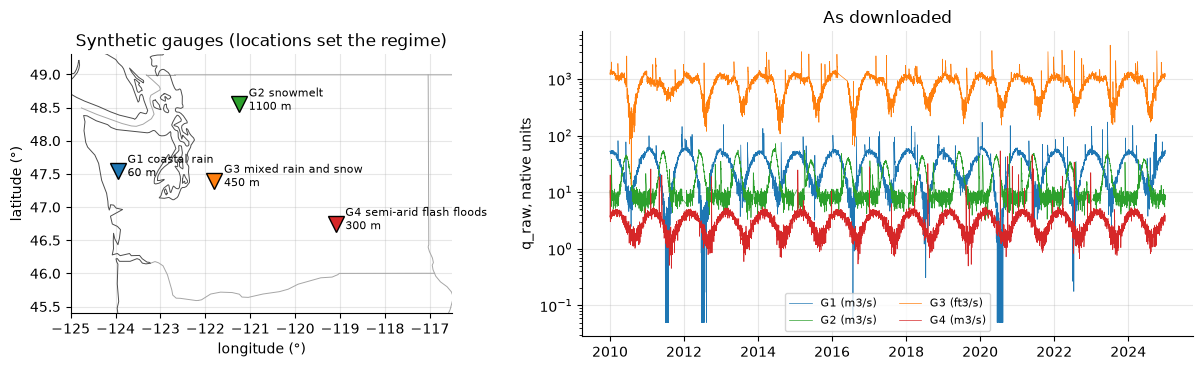

In [3]:
plot_raw(raw)

G3 sits a factor of 35 above the others: the ratio between a cubic meter and a cubic foot. The map uses Natural Earth coastlines and borders (course copy in `snapshots/`); the gauge positions are chosen to match the regimes, not real gauges.

## 3. Analysis readiness (A1 to A4)

### A1 Provenance

Every value here comes from `mlgeo_synth` with fixed seeds (11 to 14, one per gauge); the background equations and flood parameters are in the setup cell. The dataset is entirely synthetic, which must be stated in its description. For a real download, A1 asks for the provider (for example, USGS National Water Information System), the gauge numbers, the retrieval date, the data version (provisional or approved records), the license and the citation. We write these in the description in A4.

### A2 Homogenization: units and time base

**Your turn: convert to one unit and check the time base.** Write `q_m3s`, the discharge of every row of `raw` in m³/s (multiply by 0.0283168 where the gauge reports ft³/s, using `GAUGES['units']`), and `steps`, the count of each interval in days between consecutive dates of the same gauge.

*Hint:* `np.where(raw['gauge_id'].map(GAUGES['units']) == 'ft3/s', 0.0283168, 1.0)`; `raw.groupby('gauge_id')['date'].diff().dt.days.value_counts()`.

In [6]:
# --- your code
q_m3s = raw["q_raw"] * np.where(raw['gauge_id'].map(GAUGES['units']) == 'ft3/s', 0.0283168, 1.0)    # Series, same rows as raw, in m3/s
steps = raw.groupby('gauge_id')['date'].diff().dt.days.value_counts()    # Series: interval in days -> number of occurrences
# --- end
your_turn("A2", globals())

[A2] correct


*Worked solution below (click ⋯ to open).*

In [8]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
q_m3s_sol = raw["q_raw"] * np.where(raw["gauge_id"].map(GAUGES["units"]) == "ft3/s", 0.0283168, 1.0)
steps_sol = raw.groupby("gauge_id")["date"].diff().dt.days.value_counts()
print(steps_sol)

date
1.0     21821
91.0        1
Name: count, dtype: int64


In [11]:
print(steps)
# one row per gauge and day: the missing rows become NaN, and the labels are carried along
daily = (raw.assign(q_m3s=q_m3s).drop(columns="q_raw").set_index(["gauge_id", "date"])
         .reindex(pd.MultiIndex.from_product([GAUGES.index, DATES], names=["gauge_id", "date"])).reset_index())
daily[["flood", "event_id"]] = daily[["flood", "event_id"]].fillna({"flood": 0, "event_id": -1}).astype(int)
print(daily.shape)

date
1.0     21821
91.0        1
Name: count, dtype: int64
(21916, 5)


One step of 91 days: G3 lost three months of rows in 2016. A gap encoded as absent rows is invisible to anyone who looks at the table without checking the time step. After `reindex` the outage is explicit NaN.

### A3 Quality and gaps

**Your turn: count sentinels and gaps.** Write `n_sentinel`, the number of -999 values per gauge in `daily['q_m3s']`; `q_clean`, the same column with -999 replaced by NaN; and `n_missing`, the number of NaN per gauge in `q_clean`.

*Hint:* `(daily['q_m3s'] == -999).groupby(daily['gauge_id']).sum()`; `Series.replace(-999, np.nan)`; `isna()`.

In [16]:
# --- your code
n_sentinel = (daily['q_m3s'] == -999).groupby(daily['gauge_id']).sum()   # Series per gauge
q_clean = daily['q_m3s'].replace(-999, np.nan)      # Series, same rows as daily
n_missing = q_clean.isna().groupby(daily['gauge_id']).sum()    # Series per gauge
# --- end
your_turn("A3", globals())

[A3] correct


*Worked solution below (click ⋯ to open).*

In [19]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
n_sentinel_sol = (daily["q_m3s"] == -999).groupby(daily["gauge_id"]).sum()
q_clean_sol = daily["q_m3s"].replace(-999, np.nan)
n_missing_sol = q_clean_sol.isna().groupby(daily["gauge_id"]).sum()

          sentinel -999  missing after cleaning
gauge_id                                       
G1                    0                       0
G2                  144                     144
G3                    0                      90
G4                    0                       3


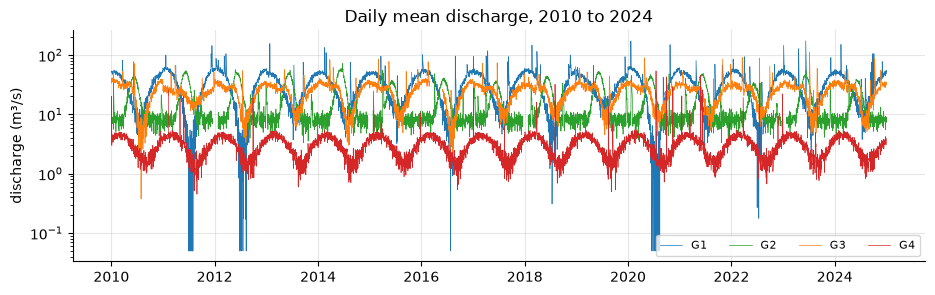

In [20]:
daily["q_m3s"] = q_clean
print(pd.DataFrame({"sentinel -999": n_sentinel, "missing after cleaning": n_missing}))
fig, ax = plt.subplots(figsize=(11, 3))
plot_series(daily, ax)

Three gap mechanisms, and they are not equivalent:

- **G2, ice** (-999, 36 days in each of four winters): ice on the channel control makes the rating curve invalid. The flow is not zero and not unknown in the same way as an outage: it is low winter flow, censored by the method. Had we left -999 in place, the mean winter flow would be negative.
- **G3, outage** (90 days in spring 2016): missing for reasons unrelated to the flow. Interpolating is defensible for a slowly varying series, not across a flood.
- **G4, sensor lost at the peak** (3 days): missing *because* the flow was extreme. Every statistic of flood peaks at G4 is biased low, and a model never sees the largest flood. This is informative missingness, and it is common: gauges fail during the floods they were built for.

### A4 Structure and metadata

The table `daily` is tidy: one row per gauge and day, one column per variable. The description of the dataset travels with it as a YAML file next to a Parquet copy of the table. Part of it is written below; you complete it.

In [35]:
description = {
    "name": "synthetic_wa_gauges_floods",
    "version": "2026.10",
    "provenance": {"synthetic": True, "generator": "mlgeo_synth.inject_rare_events, seeds 11-14",
                   "license": "CC-BY-4.0", "citation": "MLGeo course materials, University of Washington, 2026"},
    "time_base": {"sampling": "daily mean", "time_zone": "UTC", "start": "2010-01-01", "end": "2024-12-31"},
    "gauges": GAUGES.reset_index().to_dict("records"),
    "variables": {"gauge_id": {"units": "none"}, "date": {"units": "day"},
                  "flood": {"units": "none", "description": "1 inside a flood, from the generator"},
                  "event_id": {"units": "none", "description": "flood number per gauge, -1 outside floods"}},
}
daily.to_parquet(OUTDIR / "daily_discharge.parquet", index=False)

**Your turn: complete and read back the description.** Add the entry for `q_m3s` (units and a short description) and a `missing_values` entry that states the encoding and the three gap mechanisms; write `description` to `OUTDIR / 'description.yml'` and read the file back into `desc`.

*Hint:* `description['variables']['q_m3s'] = {...}`; `(OUTDIR / 'description.yml').write_text(yaml.safe_dump(description))`; `yaml.safe_load(...read_text())`.

In [36]:
# --- your code
# the dictionary read back from description.yml
description["variables"]["q_m3s"] = {"units": "m3/s", "description": "daily mean discharge in cubic meters per second (m³/s)"} 
description["missing_values"] = {"encoding": "NaN", "ice_sentinel": "-999 at G2, set to NaN",
                                     "gaps": "G3 outage spring 2016; G4 two days at a flood peak"}
desc = yaml.safe_load(yaml.safe_dump(description, sort_keys=False))
# --- end
your_turn("A4", globals())

[A4] correct


*Worked solution below (click ⋯ to open).*

In [25]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
description_sol = copy.deepcopy(description)
description_sol["variables"]["q_m3s"] = {"units": "m3/s", "description": "daily mean river discharge"}
description_sol["missing_values"] = {"encoding": "NaN", "ice_sentinel": "-999 at G2, set to NaN",
                                     "gaps": "G3 outage spring 2016; G4 two days at a flood peak"}
desc_sol = yaml.safe_load(yaml.safe_dump(description_sol, sort_keys=False))   # the round trip, without a file

In [13]:
# a script reads the description and checks the table against it
no_units = [c for c in daily.columns if "units" not in desc["variables"].get(c, {})]
print("columns without units:", no_units or "none")
print("synthetic disclosed:", desc["provenance"]["synthetic"], "| q_m3s:", desc["variables"]["q_m3s"])
print("files:", sorted(p.name for p in OUTDIR.iterdir()))

columns without units: none
synthetic disclosed: True | q_m3s: {'units': 'm3/s', 'description': 'daily mean river discharge'}
files: ['daily_discharge.parquet', 'description.yml']


## 4. AI readiness (B1 to B7)

### B1 Diversity

**Your turn: count units, not rows.** Write `n_rows`, `n_gauges`, `n_years` (distinct calendar years) and `n_floods` (distinct floods over all gauges; a flood is a pair gauge, event_id).

*Hint:* `len`, `nunique()`, `daily['date'].dt.year`, and `drop_duplicates()` on `['gauge_id', 'event_id']`.

In [40]:
# --- your code
n_rows, n_gauges = len(daily), daily["gauge_id"].nunique()
n_years = daily["date"].dt.year.nunique()
n_floods = len(daily.loc[daily["event_id"] >= 0, ["gauge_id", "event_id"]].drop_duplicates())
# --- end
your_turn("B1", globals())

[B1] correct


*Worked solution below (click ⋯ to open).*

In [15]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
n_rows_sol, n_gauges_sol = len(daily), daily["gauge_id"].nunique()
n_years_sol = daily["date"].dt.year.nunique()
n_floods_sol = len(daily.loc[daily["event_id"] >= 0, ["gauge_id", "event_id"]].drop_duplicates())

In [41]:
print(f"{n_rows} rows, but {n_gauges} gauges x {n_years} years = {n_gauges * n_years} gauge-years and {n_floods} floods")
print(f"flood days: {daily['flood'].sum()}, i.e. {daily['flood'].sum() / n_floods:.1f} rows per flood")

21916 rows, but 4 gauges x 15 years = 60 gauge-years and 185 floods
flood days: 943, i.e. 5.1 rows per flood


Twenty thousand rows are about two hundred independent floods at four gauges. Consecutive days are not independent samples, and a model that learns flood detection at four gauges has seen four basins, four rating curves, four climates. The number that limits what the model can learn is the number of floods and gauges.

### B2 Distribution

**Your turn: class balance and flood sizes.** Write `flood_frac`, the fraction of flood days per gauge, and `peaks`, the largest discharge of each flood (a Series indexed by gauge and event_id).

*Hint:* `groupby('gauge_id')['flood'].mean()`; `daily[daily['event_id'] >= 0].groupby(['gauge_id', 'event_id'])['q_m3s'].max()`.

In [44]:
# --- your code
flood_frac = daily.groupby('gauge_id')['flood'].mean()
peaks = daily[daily['event_id'] >= 0].groupby(['gauge_id', 'event_id'])['q_m3s'].max()
# --- end
your_turn("B2", globals())

[B2] correct


*Worked solution below (click ⋯ to open).*

In [18]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
flood_frac_sol = daily.groupby("gauge_id")["flood"].mean()
peaks_sol = daily[daily["event_id"] >= 0].groupby(["gauge_id", "event_id"])["q_m3s"].max()

flood-day fraction per gauge: {'G1': 0.05, 'G2': 0.047, 'G3': 0.063, 'G4': 0.013}


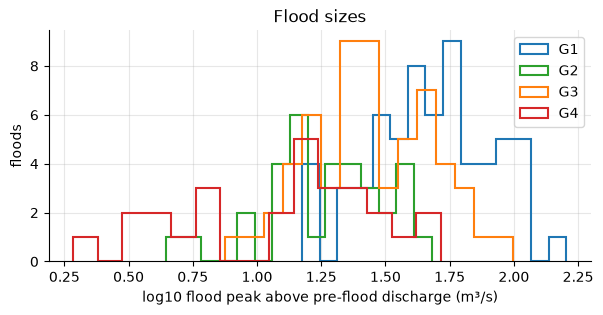

In [45]:
ev = event_table(daily)
print("flood-day fraction per gauge:", flood_frac.round(3).to_dict())
plot_flood_sizes(ev)

Between 1.3% and 6.3% of days are flood days: a model that always answers "no flood" is more than 90% accurate. We therefore score with **average precision** (AP), the area under the precision-recall curve, whose value for a random guess equals the flood fraction. The flood sizes are log-normal: the largest flood at each gauge is several times the median, and those are the floods that matter for hazard. The G4 maximum is truncated by the lost sensor (A3).

### B3 Noise characterization

The discharge has three parts: the seasonal cycle and the wet and dry years (natural variability, the signal for a water-supply question), the floods (the signal here), and measurement noise (stage sensor, rating curve). Day-to-day differences on non-flood days remove most of the seasonal cycle and keep the noise; the median absolute difference ignores the occasional jump at the end of a flood.

**Your turn: estimate the noise level and the signal-to-noise ratio.** Write `noise_sd`, the measurement noise per gauge (1.4826 times the median absolute day-to-day difference on non-flood days, divided by √2), and `snr`, the median flood excess `ev['excess']` per gauge divided by `noise_sd`.

*Hint:* `daily[daily['flood'] == 0].groupby('gauge_id')['q_m3s'].diff()`, then `.abs().groupby(daily['gauge_id']).median()`.

In [49]:
# --- your code
dq = daily[daily['flood'] == 0].groupby('gauge_id')['q_m3s'].diff()
noise_sd = 1.4826 * dq.abs().groupby(daily['gauge_id']).median() / np.sqrt(2) # Series per gauge, m3/s
snr = ev.groupby("gauge_id")["excess"].median() / noise_sd        # Series per gauge
# --- end
your_turn("B3", globals())

[B3] correct


*Worked solution below (click ⋯ to open).*

In [50]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
dq_sol = daily[daily["flood"] == 0].groupby("gauge_id")["q_m3s"].diff()
noise_sd_sol = 1.4826 * dq_sol.abs().groupby(daily["gauge_id"]).median() / np.sqrt(2)
snr_sol = ev.groupby("gauge_id")["excess"].median() / noise_sd_sol

In [48]:
print(pd.DataFrame({"estimated noise (m³/s)": noise_sd.round(2),
                    "generator truth (m³/s)": pd.Series({g: p["noise_sd"] for g, p in PARAMS.items()}),
                    "SNR of the median flood": snr.round(1)}))

    estimated noise (m³/s)  generator truth (m³/s)  SNR of the median flood
G1                    2.49                     2.5                     18.9
G2                    1.49                     1.5                     13.3
G3                    2.02                     2.0                     13.3
G4                    0.40                     0.4                     39.6


The estimate recovers the generator's noise to within a few percent. With real data there is no truth column, and the estimate is the number that goes into the description. The median flood stands 13 to 40 times above the noise: small floods are separable from noise, and the difficulty is detecting a flood before it peaks, from the days before.

### B4 Augmentation potential

Augmentation adds training samples by transforming existing ones. A transformation is valid if the result is a hydrograph the river could have produced: the same flood shifted by a few days, or the same flood with a new draw of measurement noise at the level measured in B3. Reversing time is not valid: floods rise in hours to days and recede over days to weeks, because the recession drains storage in the basin; a reversed hydrograph rises slowly and drops abruptly.

In [52]:
first = ev[ev["gauge_id"] == "G1"].sort_values("excess").iloc[-5]          # a large G1 flood
k0 = daily.index[(daily["gauge_id"] == "G1") & (daily["date"] == first["start"])][0]
window = daily.loc[k0 - 10:k0 + 29, "q_m3s"].to_numpy()                      # 40 days around it
rng_aug = np.random.default_rng(0)

**Your turn: one valid and one invalid augmentation.** Write `aug_noise`, `window` plus Gaussian noise at the level `noise_sd['G1']` drawn with `rng_aug`, and `aug_flip`, `window` reversed in time.

*Hint:* `rng_aug.normal(0, noise_sd['G1'], len(window))`; `window[::-1]`.

In [54]:
# --- your code
aug_noise = window + np.random.default_rng(0).normal(0, noise_sd["G1"], len(window))
aug_flip = window[::-1]
# --- end
your_turn("B4", globals())

[B4] correct


*Worked solution below (click ⋯ to open).*

In [55]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
aug_noise_sol = window + np.random.default_rng(0).normal(0, noise_sd["G1"], len(window))
aug_flip_sol = window[::-1]

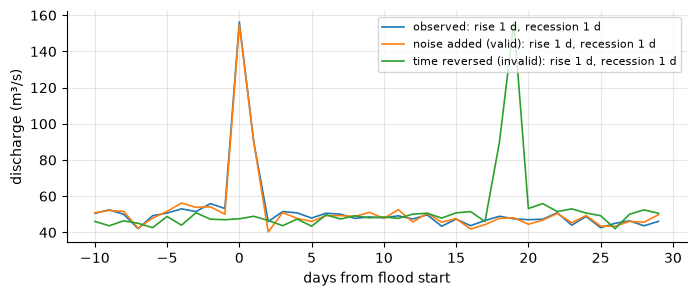

In [56]:
plot_augmentation(window, aug_noise, aug_flip)

Shifting a window in time is valid only if the label shifts with it, and a flood moved from November to August at G1 would put it in the dry season, outside the physics. Adding noise at G4 at the G1 level would produce negative discharge. Synthetic floods with known truth, like the ones in this notebook, are a third route, valid as long as their shape matches the basin (disclosed in A1).

### B5 Labels

Our labels come from the generator: exact, and unavailable for a real river. Real flood labels come from a threshold (the National Weather Service flood stage, or a percentile of discharge), from a peak-over-threshold analysis, or from reports of damage. Two labelers rarely agree on when a flood ends.

In [59]:
daily["q95"] = daily.groupby("gauge_id")["q_m3s"].transform(lambda s: s.quantile(0.95))   # 95th percentile per gauge

**Your turn: compare two labelers.** Write `label_thr`, 1 where `q_m3s` exceeds the gauge's 95th percentile `q95`, `agree`, the fraction of days where `label_thr` equals `flood`, and `missed`, the fraction of generator flood days that the threshold labels 0.

*Hint:* `(daily['q_m3s'] > daily['q95']).astype(int)`; `.mean()`; `((label_thr == 0) & (daily['flood'] == 1)).sum()`.

In [67]:
# --- your code
label_thr = (daily['q_m3s'] > daily['q95']).astype(int)
agree = (label_thr == daily["flood"]).mean()
missed = ((label_thr == 0) & (daily["flood"] == 1)).sum() / daily["flood"].sum()
# --- end
your_turn("B5", globals())

[B5] correct


*Worked solution below (click ⋯ to open).*

In [68]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
label_thr_sol = (daily["q_m3s"] > daily["q95"]).astype(int)
agree_sol = (label_thr_sol == daily["flood"]).mean()
missed_sol = ((label_thr_sol == 0) & (daily["flood"] == 1)).sum() / daily["flood"].sum()

In [69]:
print(f"agreement {agree:.3f}; the threshold misses {missed:.0%} of the generator's flood days")
print(pd.crosstab(daily["flood"], label_thr, rownames=["generator"], colnames=["threshold"]))

agreement 0.947; the threshold misses 54% of the generator's flood days
threshold      0    1
generator            
0          20319  654
1            512  431


The agreement looks high only because most days are dry days on which both labelers say 0. The threshold misses the small floods during the high season and the recession tails, and flags high seasonal flow (G2 freshet) that is not a flood. Labels with this kind of disagreement are common; the description should state which definition was used. For self-supervised learning the situation is favorable: decades of unlabeled daily discharge at thousands of gauges exist, with strong structure (seasonality, recessions) that a model can learn before it sees any label.

### B6 Dimensionality

The input of the flood detector is a window of seven daily discharges plus the day of year (as sine and cosine): nine features per sample.

In [71]:
FEATS = [f"q_lag{k}" for k in range(1, 8)] + ["doy_sin", "doy_cos"]
feat = daily[["gauge_id", "date", "flood", "event_id"]].copy()
for k in range(1, 8):
    feat[f"q_lag{k}"] = daily.groupby("gauge_id")["q_m3s"].shift(k)
feat["doy_sin"], feat["doy_cos"] = np.sin(2 * np.pi * daily["date"].dt.dayofyear / 365.25), np.cos(2 * np.pi * daily["date"].dt.dayofyear / 365.25)
feat = feat.dropna().reset_index(drop=True)
X, y = feat[FEATS], feat["flood"]
print(X.shape)

(21615, 9)


**Your turn: variance explained by principal components.** Write `cum_var`, the cumulative fraction of variance explained by the principal components of the standardized feature table `X`.

*Hint:* `PCA().fit(StandardScaler().fit_transform(X))`, then `np.cumsum(pca.explained_variance_ratio_)`.

In [75]:
# --- your code
pca = PCA().fit(StandardScaler().fit_transform(X))    # array of 9 values, increasing to 1
cum_var = np.cumsum(pca.explained_variance_ratio_)
# --- end
your_turn("B6", globals())

[B6] correct


*Worked solution below (click ⋯ to open).*

In [76]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
pca_sol = PCA().fit(StandardScaler().fit_transform(X))
cum_var_sol = np.cumsum(pca_sol.explained_variance_ratio_)

In [77]:
print("cumulative variance explained:", np.round(cum_var, 3))

cumulative variance explained: [0.736 0.848 0.945 0.966 0.978 0.986 0.991 0.996 1.   ]


About 20,000 samples for 9 features is a comfortable ratio for a random forest. The first principal component alone explains about three quarters of the variance: seven consecutive days of discharge are nearly copies of each other, and the intrinsic dimension of the window is closer to three (level, day of year as two components) than to nine. That redundancy is also why neighboring days are near-copies of each other, the problem of B7.

### B7 Partitioning: within domain and out of domain

**Training and validation** sets come from the same domain; validation tests interpolation and is used to choose settings. The **test** set comes from outside the training domain along a stated axis, and tests generalization. We define the domain as gauges G1 to G3, years 2010 to 2021. Validation is 20% of the gauge-months of that domain, held out as whole months so that consecutive days do not straddle the split. Everything else is out of domain: the years 2022 to 2024 (time) and gauge G4 (space). One model, a random forest classifier, for all the tests.

In [79]:
year = feat["date"].dt.year
in_domain = feat["gauge_id"].isin(["G1", "G2", "G3"]) & (year <= 2021)
months = feat["gauge_id"] + feat["date"].dt.strftime("%Y-%m")
tr_idx, va_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
                      .split(feat[in_domain], groups=months[in_domain]))
is_train = feat.index.isin(feat[in_domain].index[tr_idx])
X_train, y_train = X[is_train], y[is_train]
X_eval, y_eval = X[~is_train], y[~is_train].to_numpy()
is_val = in_domain[~is_train].to_numpy()
is_late = (~in_domain & (feat["gauge_id"] != "G4"))[~is_train].to_numpy()
is_g4 = (feat["gauge_id"] == "G4")[~is_train].to_numpy()
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=3, class_weight="balanced", n_jobs=-1, random_state=0)
rf.fit(X_train, y_train)
p_eval = rf.predict_proba(X_eval)[:, 1]
print(f"train {is_train.sum()}, validation {is_val.sum()}, last years {is_late.sum()}, gauge G4 {is_g4.sum()} samples")

train 10301, validation 2605, last years 3246, gauge G4 5463 samples


#### Statistical axis: distance to the training set

A sample is out of domain statistically if it lies far from every training sample in feature space. We measure the distance to the nearest training sample after standardizing the features with the **training** mean and standard deviation (standardizing with all the data would leak the test distribution into the scale). A sample is "outside" if its distance exceeds the 95th percentile of the distances between each training sample and its nearest other training sample.

**Your turn: distances to the training set.** Fit `scaler` on `X_train` only; write `d_train`, the distance from each training sample to its nearest *other* training sample, `d_eval`, the distance from each row of `X_eval` to its nearest training sample, `d_cut`, the 95th percentile of `d_train`, and `outside`, True where `d_eval` exceeds `d_cut`.

*Hint:* `NearestNeighbors(n_neighbors=2).fit(Z_train)`; `nn.kneighbors(Z_train)[0][:, 1]`; `nn.kneighbors(Z_eval, n_neighbors=1)[0][:, 0]`; `np.percentile`.

In [80]:
# --- your code
scaler = StandardScaler().fit(X_train)
nn = NearestNeighbors(n_neighbors=2).fit(scaler.transform(X_train))
d_train = nn.kneighbors(scaler.transform(X_train))[0][:, 1]
d_eval = nn.kneighbors(scaler.transform(X_eval), n_neighbors=1)[0][:, 0]
d_cut = np.percentile(d_train, 95)
outside = d_eval > d_cut    # True where d_eval > d_cut
# --- end
your_turn("B7.stat", globals())

[B7.stat] correct


*Worked solution below (click ⋯ to open).*

In [37]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
scaler_sol = StandardScaler().fit(X_train)
nn_sol = NearestNeighbors(n_neighbors=2).fit(scaler_sol.transform(X_train))
d_train_sol = nn_sol.kneighbors(scaler_sol.transform(X_train))[0][:, 1]
d_eval_sol = nn_sol.kneighbors(scaler_sol.transform(X_eval), n_neighbors=1)[0][:, 0]
d_cut_sol = np.percentile(d_train_sol, 95)
outside_sol = d_eval_sol > d_cut_sol

21% of evaluation samples are outside; mean squared error: validation 0.0324, outside 0.1109
flood days: 2.1% of samples inside, 9.0% outside
share outside: validation 6%, last years 8%, gauge G4 36%


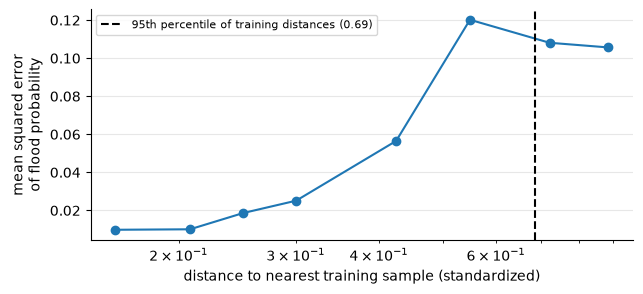

In [97]:
plot_error_vs_distance(d_eval, d_cut, p_eval, y_eval)
bs_val, bs_out = (np.mean((p_eval[m] - y_eval[m]) ** 2) for m in (is_val, outside))
print(f"{outside.mean():.0%} of evaluation samples are outside; mean squared error: validation {bs_val:.4f}, outside {bs_out:.4f}")
print(f"flood days: {y_eval[~outside].mean():.1%} of samples inside, {y_eval[outside].mean():.1%} outside")
print("share outside: validation {:.0%}, last years {:.0%}, gauge G4 {:.0%}".format(*(outside[m].mean() for m in (is_val, is_late, is_g4))))

The error grows with distance from the training set. The far samples are the rare states of the river: flood days, which the training set covers thinly, and G4, a third of whose days are outside. Few validation samples are outside, as expected for a within-domain set. The distance needs no label, so it can be computed for any new sample before the model is trusted with it.

#### Spatiotemporal axis: held-out years and a held-out gauge

**Your turn: score each partition.** Write `ap_val`, `ap_late` and `ap_gauge`, the average precision of `p_eval` against `y_eval` on the validation samples, the last years, and gauge G4.

*Hint:* `average_precision_score(y_eval[is_val], p_eval[is_val])`, and the same with `is_late` and `is_g4`.

In [81]:
# --- your code
ap_val = average_precision_score(y_eval[is_val], p_eval[is_val])
ap_late = average_precision_score(y_eval[is_late], p_eval[is_late])
ap_gauge = average_precision_score(y_eval[is_g4], p_eval[is_g4])
# --- end
your_turn("B7.space", globals())

[B7.space] correct


*Worked solution below (click ⋯ to open).*

In [40]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
ap_val_sol = average_precision_score(y_eval[is_val], p_eval[is_val])
ap_late_sol = average_precision_score(y_eval[is_late], p_eval[is_late])
ap_gauge_sol = average_precision_score(y_eval[is_g4], p_eval[is_g4])

In [95]:
# the same model with a random 80/20 split of all rows, the split most often used
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)
ap_random = average_precision_score(yr_te, clone(rf).fit(Xr_tr, yr_tr).predict_proba(Xr_te)[:, 1])
print(f"AP random split {ap_random:.3f} | validation {ap_val:.3f} | last years {ap_late:.3f} | gauge G4 {ap_gauge:.3f}")

AP random split 0.736 | validation 0.739 | last years 0.703 | gauge G4 0.200


The random split and the validation score about the same, and both look good. The random split, though, has G4 days in its training set, so its score is a statement about gauges the model has already seen. The held-out years score close to validation, because 2022 to 2024 at G1 to G3 come from the same climate and rating curves. The held-out gauge scores far lower: G4 floods of 10 to 20 m³/s look like ordinary winter flow at G1. A random split would have hidden that a flood detector built this way does not transfer to a new basin.

Cross-validation at G1 alone (5 folds each): shuffled `KFold` scatters the days of each flood over training and test folds, `TimeSeriesSplit` trains on the past only, `GroupKFold` keeps each flood, and each 30-day block of dry days, in one fold.

In [86]:
g1 = feat[feat["gauge_id"] == "G1"].reset_index(drop=True)
groups = np.where(g1["event_id"] >= 0, g1["event_id"], 1000 + np.arange(len(g1)) // 30)
rf_cv = RandomForestClassifier(n_estimators=100, class_weight="balanced", n_jobs=-1, random_state=0)
for name, cv in [("KFold, shuffled", KFold(5, shuffle=True, random_state=0)), ("TimeSeriesSplit", TimeSeriesSplit(5)),
                 ("GroupKFold by flood", GroupKFold(5))]:
    s = cross_val_score(rf_cv, g1[FEATS], g1["flood"], cv=cv, scoring="average_precision",
                        groups=groups if isinstance(cv, GroupKFold) else None)
    print(f"{name:20s} AP = {s.mean():.3f} ± {s.std():.3f}")

KFold, shuffled      AP = 0.730 ± 0.032
TimeSeriesSplit      AP = 0.642 ± 0.105
GroupKFold by flood  AP = 0.707 ± 0.045


Shuffled `KFold` scores a little above `GroupKFold`. The gap is small on this dataset: measurement noise keeps neighboring days from being copies of each other, and a flood is detected from its rise over the last two or three days. It grows with smooth inputs (30-day means, snowpack, soil moisture), whose neighboring values are nearly identical. `TimeSeriesSplit` scores lowest, partly because its first folds train on three years only.

**Leakage by preprocessing.** Every statistic computed from the data (a mean, a standard deviation, a PCA basis, a percentile, an imputation value) becomes part of the model. Computed on all the data before splitting, it carries information from the test set into training. Two cases: a scaler, and oversampling the rare class.

In [87]:
test_late = ~in_domain & (feat["gauge_id"] != "G4")
for label, sc in [("scaler fit on all data", StandardScaler().fit(X)), ("scaler fit on training only", StandardScaler().fit(X_train))]:
    lr = LogisticRegression(max_iter=2000, class_weight="balanced").fit(sc.transform(X_train), y_train)
    print(f"{label:28s} AP last years = {average_precision_score(y[test_late], lr.predict_proba(sc.transform(X[test_late]))[:, 1]):.3f}")

Xa, ya = g1[FEATS].to_numpy(), g1["flood"].to_numpy()
up = resample(Xa[ya == 1], n_samples=int((ya == 0).sum()), random_state=0)       # duplicate flood days
Xb, yb = np.vstack([Xa[ya == 0], up]), np.r_[ya[ya == 0], np.ones(len(up))]
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.3, random_state=0, stratify=yb)
ap_leak = average_precision_score(yb_te, clone(rf_cv).fit(Xb_tr, yb_tr).predict_proba(Xb_te)[:, 1])
print(f"oversampling before the split: AP = {ap_leak:.3f} (copies of the same flood day on both sides)")

scaler fit on all data       AP last years = 0.528
scaler fit on training only  AP last years = 0.528
oversampling before the split: AP = 1.000 (copies of the same flood day on both sides)


The scaler barely changes the score here: a long, stationary record and two numbers per feature. The gap grows with short records, drifting test periods and richer preprocessing (PCA, imputation, feature selection). Oversampling before the split produces a near-perfect score that measures nothing. Rule: split first, then fit every preprocessing step, and resample, on the training set only.

#### Physical axis: floods larger than any in training

Hazard models are judged on the largest floods, which are by definition the rarest in any record. We pose a regression: estimate the flood peak above the pre-flood discharge (`excess`) from what is known in the first two days (`q0`, `rise1`, `rise2`), the season and the gauge's mean flow. We train on floods whose excess is below the 80th percentile of all floods, and test on the larger ones.

In [89]:
EV_FEATS = ["q0", "rise1", "rise2", "doy", "qmean"]
ev["thr"] = ev["excess"].quantile(0.8)        # 80th percentile of all flood sizes
peak_model = RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=0)
print(f"{(ev['excess'] <= ev['thr']).sum()} floods below the threshold, {(ev['excess'] > ev['thr']).sum()} above")

145 floods below the threshold, 37 above


**Your turn: train on small floods, test on large ones.** Write `small`, True for floods with `excess <= thr`; fit `peak_model` on the small floods; write `pred_large`, its estimate for the large floods, and `ratio_large`, the median of estimated over observed excess for the large floods.

*Hint:* `peak_model.fit(ev.loc[small, EV_FEATS], ev.loc[small, 'excess'])`; `np.median(pred_large / ev.loc[~small, 'excess'])`.

In [90]:
# --- your code
small = ev["excess"] <= ev["thr"]
model = clone(peak_model).fit(ev.loc[small, EV_FEATS], ev.loc[small, 'excess'])
pred_large = model.predict(ev.loc[~small, EV_FEATS])
ratio_large = np.median(pred_large / ev.loc[~small, 'excess'])
# --- end
your_turn("B7.phys", globals())

[B7.phys] correct


*Worked solution below (click ⋯ to open).*

In [93]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
small_sol = ev["excess"] <= ev["thr"]
model_sol = clone(peak_model).fit(ev.loc[small_sol, EV_FEATS], ev.loc[small_sol, "excess"])
pred_large_sol = model_sol.predict(ev.loc[~small_sol, EV_FEATS])
ratio_large_sol = np.median(pred_large_sol / ev.loc[~small_sol, "excess"])

median estimated/observed: small floods 1.00, large floods 0.69 (linear model 0.99)


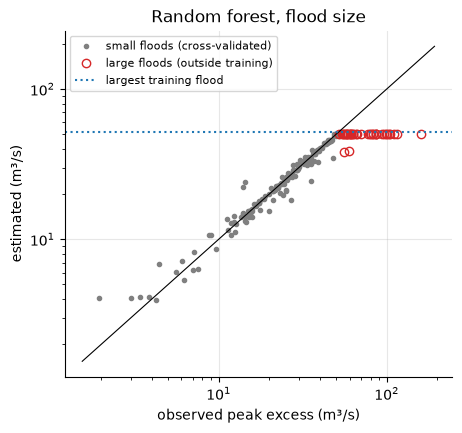

In [91]:
small = ev["excess"] <= ev["thr"]
pred_small = np.zeros(small.sum())     # within domain: 5-fold cross-validation on the small floods
for a, b in KFold(5, shuffle=True, random_state=0).split(ev[small]):
    pred_small[b] = clone(peak_model).fit(ev[small].iloc[a][EV_FEATS], ev[small].iloc[a]["excess"]).predict(ev[small].iloc[b][EV_FEATS])
ratio_small = np.median(pred_small / ev.loc[small, "excess"])
lin = LinearRegression().fit(ev.loc[small, EV_FEATS], ev.loc[small, "excess"])
ratio_lin = np.median(lin.predict(ev.loc[~small, EV_FEATS]) / ev.loc[~small, "excess"])
plot_peaks(ev, small, pred_small, pred_large)
print(f"median estimated/observed: small floods {ratio_small:.2f}, large floods {ratio_large:.2f} (linear model {ratio_lin:.2f})")

The forest cannot return a value larger than the training targets it averages, so every large flood is capped near the largest training flood and underestimated. A linear model extrapolates, and does well here only because the synthetic flood shape is linear in amplitude by construction. Real rivers change physics as floods grow: water leaves the channel onto the floodplain, and the rating curve itself is extrapolated above the largest measured flow. The physical axis tests whether the model has learned something that holds outside the range of sizes it was shown.

In [98]:
summary = pd.DataFrame([
    ["random 80/20 split, all rows", "none", "AP (1 is best)", ap_val, ap_random, "interpolation, G4 days included in training"],
    ["validation, held-out months", "within domain", "AP (1 is best)", ap_val, ap_val, "interpolation inside G1-G3, 2010-2021"],
    ["beyond 95th percentile distance", "statistical", "squared error of p (0 is best)", bs_val, bs_out, "samples unlike any training sample"],
    ["years 2022-2024, G1-G3", "spatiotemporal", "AP (1 is best)", ap_val, ap_late, "same gauges, later period"],
    ["gauge G4", "spatiotemporal", "AP (1 is best)", ap_val, ap_gauge, "a new basin and climate"],
    ["floods above the 80th percentile", "physical", "median estimated/observed peak", ratio_small, ratio_large, "flood sizes larger than any in training"],
], columns=["partition", "axis", "metric", "within domain", "this partition", "what it measures"])
summary.round(3)

,partition,axis,metric,within domain,this partition,what it measures
0,"random 80/20 split, all rows",none,AP (1 is best),0.739,0.736,"interpolation, G4 days included in training"
1,"validation, held-out months",within domain,AP (1 is best),0.739,0.739,"interpolation inside G1-G3, 2010-2021"
2,beyond 95th percentile distance,statistical,squared error of p (0 is best),0.032,0.111,samples unlike any training sample
3,"years 2022-2024, G1-G3",spatiotemporal,AP (1 is best),0.739,0.703,"same gauges, later period"
4,gauge G4,spatiotemporal,AP (1 is best),0.739,0.200,a new basin and climate
5,floods above the 80th percentile,physical,median estimated/observed peak,1.000,0.689,flood sizes larger than any in training


Report the out-of-domain scores with their axis. The validation score tells you the model learned the training domain; only the test scores tell you where it can be used.

## 5. Score this dataset on the rubric

Give each criterion 0, 1 or 2 and one line of evidence from this notebook. Be strict: 2 means another team could verify it from the files in `data/ai_ready_demo/` and this notebook.

In [99]:
# --- your scores: (0, 1 or 2, "one line of evidence")
scores = {
    "A1 provenance": (2, "generator, seeds, license, citation in description.yml; synthetic disclosed"),
    "A2 homogenization": (2, "G3 converted from ft3/s; daily UTC time base; outage made explicit by reindexing"),
    "A3 quality and gaps": (2, "ice sentinel, outage and lost-sensor gap counted, set to NaN, mechanisms stated"),
    "A4 structure and metadata": (2, "tidy Parquet table and YAML description read back by a script"),
    "B1 diversity": (1, "about 200 floods but only 4 gauges in one state, one generator"),
    "B2 distribution": (1, "imbalance and log-normal sizes measured; real flood population unknown for synthetic data"),
    "B3 noise": (2, "noise level per gauge estimated and checked against the generator; SNR of the median flood"),
    "B4 augmentation": (1, "noise and time shifts valid, reversal invalid; not tested for skill"),
    "B5 labels": (1, "exact generator labels; threshold labeler disagrees on small floods and recessions"),
    "B6 dimensionality": (2, "9 features, ~20,000 samples, first component ~3/4 of the variance"),
    "B7 partitioning": (2, "within-domain validation and tests on three axes, preprocessing fit on training only"),
}
# --- end
check_scores(scores)

[rubric] 11 of 11 criteria scored with evidence
total: 18 of 22


*One instructor scoring below (click ⋯ to open). Discuss where yours differs.*

In [50]:
# One instructor scoring
scores_sol = {
    "A1 provenance": (2, "generator, seeds, license, citation in description.yml; synthetic disclosed"),
    "A2 homogenization": (2, "G3 converted from ft3/s; daily UTC time base; outage made explicit by reindexing"),
    "A3 quality and gaps": (2, "ice sentinel, outage and lost-sensor gap counted, set to NaN, mechanisms stated"),
    "A4 structure and metadata": (2, "tidy Parquet table and YAML description read back by a script"),
    "B1 diversity": (1, "about 200 floods but only 4 gauges in one state, one generator"),
    "B2 distribution": (1, "imbalance and log-normal sizes measured; real flood population unknown for synthetic data"),
    "B3 noise": (2, "noise level per gauge estimated and checked against the generator; SNR of the median flood"),
    "B4 augmentation": (1, "noise and time shifts valid, reversal invalid; not tested for skill"),
    "B5 labels": (1, "exact generator labels; threshold labeler disagrees on small floods and recessions"),
    "B6 dimensionality": (2, "9 features, ~20,000 samples, first component ~3/4 of the variance"),
    "B7 partitioning": (2, "within-domain validation and tests on three axes, preprocessing fit on training only"),
}
check_scores(scores_sol)

[rubric] 11 of 11 criteria scored with evidence
total: 18 of 22


## 6. Your project dataset

Apply the same rubric to your project dataset: one score and one line of evidence per criterion, and the files or notebook cells that support each 2. For B7, name the axis of your test set and the independent unit you split by. The rubric is part of the project milestone; see the [chapter assignment](2.20_Final_Project_Assignement.md) and the [final project description](../about_this_book/1.10_MLGEO_FinalProject.md).